# Champion Base Stats
##Distribution Analysis: HP, Armor & Move Speed
### Key Insights & Observations

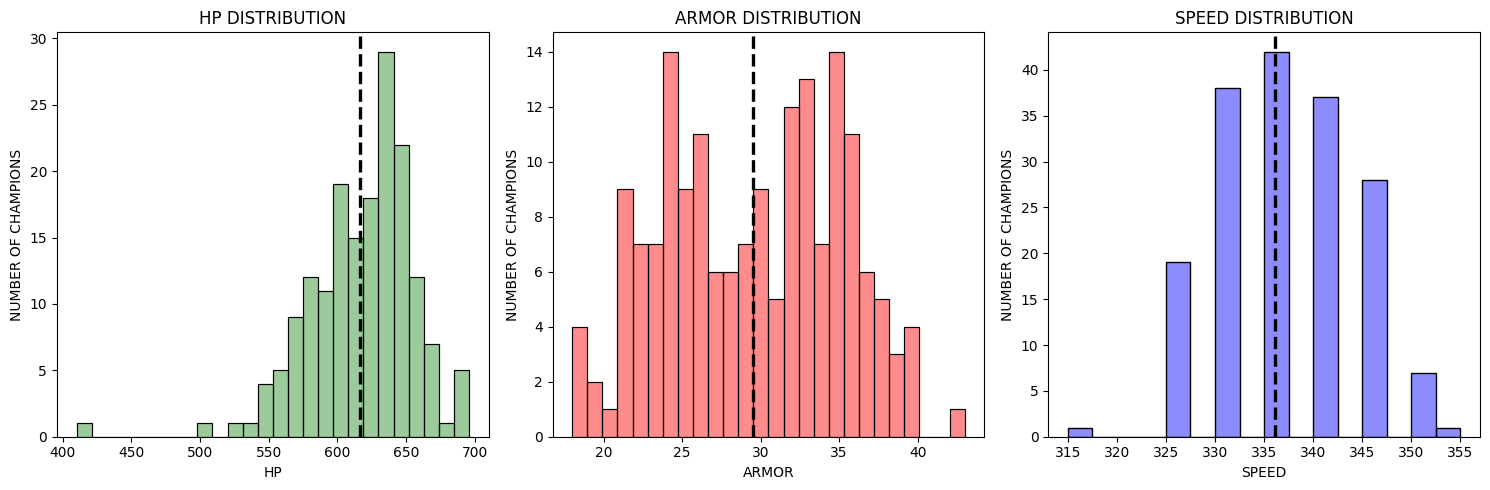

In [125]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

df=ROLS_ANALYSIS_CSV

df_Sorted_by_hp=df.sort_values(by='hp',ascending=True)

bincount=int(2*np.sqrt(len(df)))

fig,axes=plt.subplots(1,3,figsize=(15,5))

sns.histplot(data=df_Sorted_by_hp,x='hp',color='#228B22',alpha=0.45,ax=axes[0],bins=bincount)
axes[0].set_title('HP DISTRIBUTION')
axes[0].set_xlabel('HP')
axes[0].set_ylabel('NUMBER OF CHAMPIONS')

axes[0].axvline(df['hp'].mean(), color='#000000', linestyle='--', linewidth=2.4,
                label=f"MEAN{df['hp'].mean():.0f}")


sns.histplot(data=df_Sorted_by_hp,x='stats.armor',color='#FF0000',alpha=0.45,ax=axes[1],bins=bincount)
axes[1].set_title('ARMOR DISTRIBUTION')
axes[1].set_xlabel('ARMOR')
axes[1].set_ylabel('NUMBER OF CHAMPIONS')

axes[1].axvline(df['stats.armor'].mean(),color="#000000",linestyle='--',linewidth=2.4)

sns.histplot(data=df_Sorted_by_hp,x='move_speed',ax=axes[2],color='#0000FF',alpha=0.45,bins=bincount-10)
axes[2].set_title('SPEED DISTRIBUTION')
axes[2].set_xlabel('SPEED')
axes[2].set_ylabel('NUMBER OF CHAMPIONS')

axes[2].axvline(df['move_speed'].mean(),color='#000000',linestyle='--',linewidth=2.4)


# sns.kdeplot(data=df_Sorted_by_hp,ax="",'KERNEL DISTRIBUTION ESTIMATION')

plt.tight_layout()
plt.show()

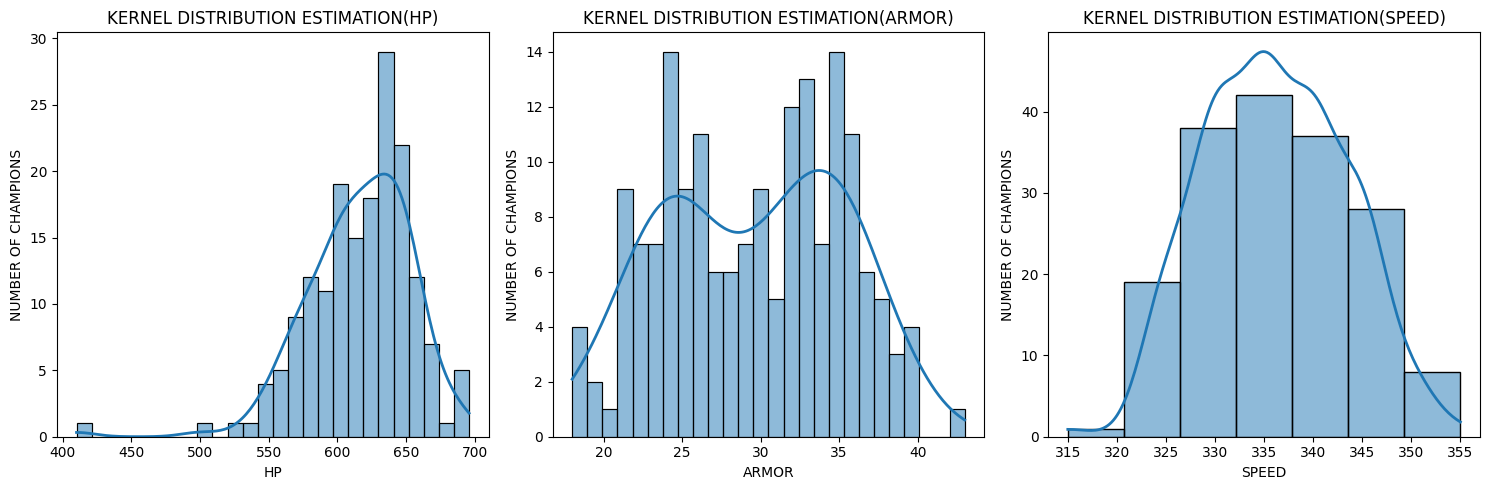

In [126]:
fig,axes=plt.subplots(1,3,figsize=(15,5))

sns.histplot(data=df_Sorted_by_hp,x='hp',ax=axes[0],bins=bincount,
             kde=True,line_kws={'color':'#FF0000',
                                 'linewidth':2})
axes[0].set_title('KERNEL DISTRIBUTION ESTIMATION(HP)')
axes[0].set_xlabel('HP')
axes[0].set_ylabel('NUMBER OF CHAMPIONS')

sns.histplot(data=df_Sorted_by_hp,x='stats.armor',ax=axes[1],bins=bincount,
             kde=True,line_kws={'color':'#FF0000',
                                 'linewidth':2})
axes[1].set_title('KERNEL DISTRIBUTION ESTIMATION(ARMOR)')
axes[1].set_xlabel('ARMOR')
axes[1].set_ylabel('NUMBER OF CHAMPIONS')

sns.histplot(data=df_Sorted_by_hp,x='move_speed',ax=axes[2],bins=7,
             kde=True,line_kws={'color':'#FF0000',
                                 'linewidth':2})

axes[2].set_title('KERNEL DISTRIBUTION ESTIMATION(SPEED)')
axes[2].set_xlabel('SPEED')
axes[2].set_ylabel('NUMBER OF CHAMPIONS')

plt.tight_layout()
plt.show()

         name  stats.armor
71      Leona           43
4     Alistar           40
78   Malphite           40
100  Pantheon           40
136     Taric           40
           name  stats.armor
22   Cassiopeia           18
79     Malzahar           18
134     Taliyah           18
148      Veigar           18
7        Anivia           19


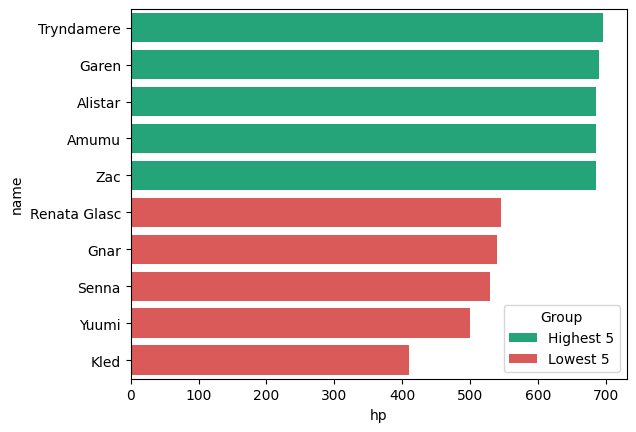

In [154]:
"""FIRST"""
FirstBar_highest=df.nlargest(5,'hp')[['name','hp']]
# print(FirstBar_highest)
FirstBar_highest['Group']='Highest 5'

FirstBar_smallest=df.nsmallest(5,'hp')[['name','hp']]
FirstBar_smallest=FirstBar_smallest.sort_values(by='hp',ascending=False)
# print(FirstBar_smallest)
FirstBar_smallest['Group']='Lowest 5'

Bar=pd.concat([FirstBar_highest,FirstBar_smallest])
# print(FirstBar[['name','hp']])

"""SECOND"""
SecondBar_highest=df.nlargest(5,'stats.armor')[['name','stats.armor']]
print(SecondBar_highest)
SecondBar_lowest=df.nsmallest(5,'stats.armor')[['name','stats.armor']]
print(SecondBar_lowest)

"""PLOT"""

# fig,axes=plt.subplot(1,3,figsize(20,6))

# sns.barplot(data)

sns.barplot(data=Bar,
            x='hp',
            y='name',
            hue='Group',
            palette={
                'Highest 5':'#10b981',
                'Lowest 5':'#ef4444'
            }
            )
plt.show()

#Takeaways from the Distributions

 **HP (Health) Distribution:** The majority of champions cluster between **580 and 660 HP**,with an average around **615 HP**.

 A notable lower outlier appears near **410 HP** (Kled), driven by unique champion mechanics
 **Armor Distribution (Bimodal):** The distribution displays two distinct peaks—one around **24–26** and another around **32–35**

 This reflects the core class split between **Ranged** champions (lower base armor) and **Melee** champions (higher base armor).
 **Move Speed Distribution:** Base movement speed is distributed across discrete tiers (**325, 330, 335, 340, 345**), centering around a mean of **~336**
 .